In [317]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

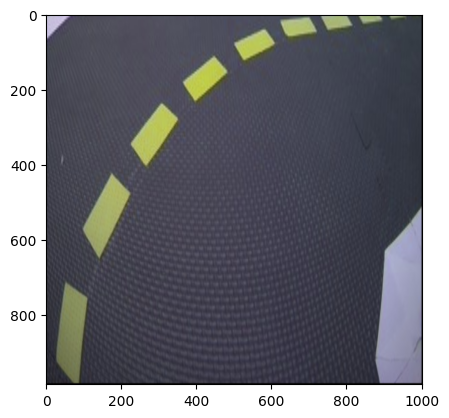

In [318]:
img = cv2.imread('lane2.png')
plt.imshow(img[:,:,(1,2,0)])
hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)


In [319]:
class LaneDetector:
    def __init__(self):
        self.distance_look_ahead = 0.75



        # init white line parameters
        self.hue_white_l = 0
        self.hue_white_h = 255
        self.saturation_white_l = 0
        self.saturation_white_h = 50
        self.lightness_white_l = 160
        self.lightness_white_h = 255
        
        # init yellow line parameters
        self.hue_yellow_l = 15
        self.hue_yellow_h = 60
        self.saturation_yellow_l = 60
        self.saturation_yellow_h = 255
        self.lightness_yellow_l = 120
        self.lightness_yellow_h = 255
        pass


    def get_x_for_driving(self, mask, distance, no_lane_value, left_line, debug_img):
        distance = int(distance)
        grad = cv2.Sobel(mask, cv2.CV_16S, 1, 0, ksize=3, scale=1, delta=0, borderType=cv2.BORDER_DEFAULT)
        if left_line:
            grad = 0 - grad
        _,th1 = cv2.threshold(grad,127,255,cv2.THRESH_BINARY)

        a = np.where(th1 == 255)

        if left_line:
            debug_img[(a[0],a[1])] = (0,255,0)

        else:
            debug_img[(a[0],a[1])] = (255,0,0)
            

        if len(a[1]) > 10:
            return np.median(a[1])
        else:
            return no_lane_value
    
    def calculate_lane_center(self,  image, debug_img):

        mask_yellow = cv2.inRange(image, 
                           (self.hue_yellow_l,self.saturation_yellow_l, self.lightness_yellow_l), 
                           (self.hue_yellow_h,self.saturation_yellow_h, self.lightness_yellow_h),)
        
        mask_white = cv2.inRange(image, 
                           (self.hue_white_l,self.saturation_white_l, self.lightness_white_l), 
                           (self.hue_white_h,self.saturation_white_h, self.lightness_white_h),)
        
        white_alternative = int(len(image[0]) * 0.95)
        yellow_alternative = int(len(image[0]) * 0.05)

        center_white = self.get_x_for_driving(mask_white,int(len(image)*self.distance_look_ahead), white_alternative, left_line=False,debug_img=debug_img)
        center_yellow = self.get_x_for_driving(mask_yellow,int(len(image)*self.distance_look_ahead), yellow_alternative, left_line=True,debug_img=debug_img)


        debug_img[np.where(mask_yellow == 255)] = [0,255,255]
        debug_img[np.where(mask_white == 255)] = [255,255,255]



        if center_white <= center_yellow:
            if center_white > int(len(image[0]) * 0.4):
                center_yellow = yellow_alternative
            else:
                center_white = white_alternative

        print(f'white:{center_white}, yellow{center_yellow}')
        lane_center = (center_white + center_yellow) / 2

        cv2.circle(img=debug_img,center=(int(lane_center) , int(len(debug_img)/2)),radius=20,color=(0,255,0),thickness=5)
        return lane_center

In [320]:
lane_detector = LaneDetector()
lane_detector.calculate_lane_center(hsv_img, img)

white:891.0, yellow304.0


np.float64(597.5)

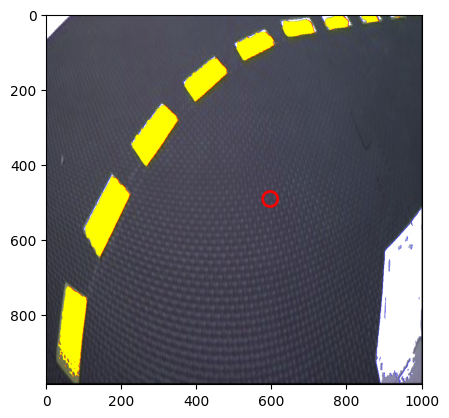

In [321]:
plt.imshow(img[:,:,(1,2,0)])